In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pickle

# Suppress warnings for cleaner output
import warnings
warnings.filterwarnings('ignore')

In [2]:
# The dataset uses a semicolon (;) as a delimiter
df = pd.read_csv('bank-full.csv', sep=';')

# Display the first few rows to verify the data loaded correctly
display(df.head())

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB
None

Missing Values in each column:
 age          0
job          0
marital      0
education    0
d

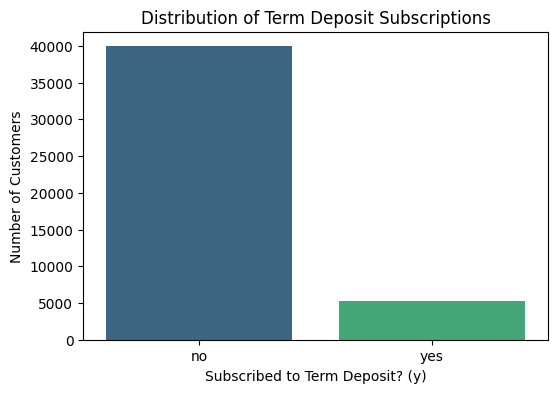

In [3]:
# Check data types and look for missing values
print(df.info())
print("\nMissing Values in each column:\n", df.isnull().sum())

# Visualize the distribution of the target variable 'y'
plt.figure(figsize=(6, 4))
sns.countplot(x='y', data=df, palette='viridis')
plt.title('Distribution of Term Deposit Subscriptions')
plt.ylabel('Number of Customers')
plt.xlabel('Subscribed to Term Deposit? (y)')
plt.show()

In [4]:
# 1. Map target variable 'y' to binary integers (0 and 1)
df['y'] = df['y'].map({'yes': 1, 'no': 0})

# 2. Extract categorical columns and apply One-Hot Encoding
categorical_cols = df.select_dtypes(include=['object']).columns
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# 3. Separate Features (X) from the Target (y)
X = df_encoded.drop('y', axis=1)
y = df_encoded['y']

print(f"Shape of Features (X): {X.shape}")
print(f"Shape of Target (y): {y.shape}")

Shape of Features (X): (45211, 42)
Shape of Target (y): (45211,)


In [5]:
# Split the data: 80% for training, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize numerical features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [6]:
# Initialize the model (increased max_iter to ensure convergence)
log_reg = LogisticRegression(max_iter=1000, random_state=42)

# Train the model
log_reg.fit(X_train_scaled, y_train)
print("Model training complete.")

Model training complete.


Accuracy Score: 0.8988

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.98      0.94      7952
           1       0.65      0.34      0.45      1091

    accuracy                           0.90      9043
   macro avg       0.78      0.66      0.70      9043
weighted avg       0.88      0.90      0.88      9043



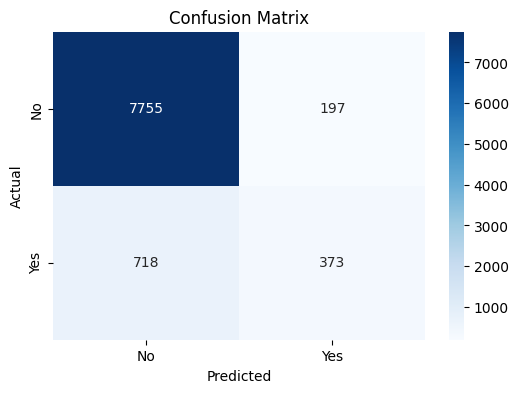

In [7]:
# Make predictions on the test set
y_pred = log_reg.predict(X_test_scaled)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy Score: {accuracy:.4f}\n")

# Display a detailed classification report
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Plot a Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

In [8]:
# 1. Save the model to disk
model_filename = 'logistic_regression_bank_model.pkl'
with open(model_filename, 'wb') as file:
    pickle.dump(log_reg, file)
print(f"Model successfully saved as: {model_filename}")

# 2. Import/Load the model from the pickle file
with open(model_filename, 'rb') as file:
    loaded_model = pickle.load(file)

# 3. Verify the loaded model works by scoring it on the test data
loaded_score = loaded_model.score(X_test_scaled, y_test)
print(f"Loaded Model Accuracy Verified: {loaded_score:.4f}")

Model successfully saved as: logistic_regression_bank_model.pkl
Loaded Model Accuracy Verified: 0.8988
